# 06 · The agent: graph, traces and recovery

The final agent (E8) is a small LangGraph state machine with hard limits. This notebook shows the graph and then reads the node-by-node log of real
runs, saved in `eval/results/`. No model is called here. To watch a live run, use `uv run python -m policy_agent.cli "<question>" --verbose`.

1. The graph
2. A calculation: two rounds of tools
3. A conflict, a clarification, an abstention and a refusal
4. What the agent does across all runs
5. Limits and recovery

In [1]:
import json
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from policy_agent.ingest.paths import ROOT

R = ROOT / "eval" / "results"
pd.set_option("display.width", 170)
dev = json.loads((R / "E8_dev.json").read_text())
test = json.loads((R / "E8T_test.json").read_text())
runs = dev["runs"] + test["runs"]
print(len(runs), "saved agent runs (dev", len(dev["runs"]), "+ held-out", len(test["runs"]), ")")


def first(case_id, runs=runs):
    return next(r for r in runs if r["case_id"] == case_id)


def show(case_id):
    r = first(case_id)
    a = r["output"]["agent"]
    print(
        f"{case_id} [{r['case_type']}] -> status {r['output']['status']}, {a['llm_calls']} model calls, {r['latency_ms'] / 1000:.1f} s, stop: {a['stop_reason']}"
    )
    for line in a["log"]:
        print("   ", line)

108 saved agent runs (dev 63 + held-out 45 )


## 1. The graph
Nodes are small functions over a shared state; the model only chooses tools (`act`) and writes the answer (`synthesize`). Everything else is ordinary code.

In [2]:
print("""
question
   |
guard_input ----(attack pattern)----> refuse ---------------------------+
   |                                                                     |
   v                                                                     |
  act  <---------------------+   model picks up to 4 tools, or stops     |
   |                         |                                           |
   v                         | insufficient evidence and budget left     |
 assess  --------------------+   (deterministic check, adds a nudge)     |
   |                                                                     |
   v sufficient, budget spent, or the model made no tool call            |
synthesize   structured Answer (JSON schema)                             |
   |                                                                     |
   v                                                                     |
validate     V1 to V6; one repair, else downgrade to abstained           |
   |                                                                     |
   v                                                                     |
output tripwire (canary or prompt marker?) ------> answer <--------------+
   |
   v (only if asked) report node: interrupt() for approval, then writes under reports/
""")
print(
    "limits: 6 tool rounds | 2 retries per tool | 1 repair | 30 s budget | 75 s hard deadline | 45 s per model call | recursion limit 25"
)


question
   |
guard_input ----(attack pattern)----> refuse ---------------------------+
   |                                                                     |
   v                                                                     |
  act  <---------------------+   model picks up to 4 tools, or stops     |
   |                         |                                           |
   v                         | insufficient evidence and budget left     |
 assess  --------------------+   (deterministic check, adds a nudge)     |
   |                                                                     |
   v sufficient, budget spent, or the model made no tool call            |
synthesize   structured Answer (JSON schema)                             |
   |                                                                     |
   v                                                                     |
validate     V1 to V6; one repair, else downgrade to abstained           |
   |       

## 2. A calculation: two rounds of tools
The model asks for the published figures and the report text in parallel. `assess` notices that the question wants a change and no change has been computed, so it sends the agent back; the arithmetic is done by a tool, never by the model.

In [3]:
show("K03")

K03 [calculation] -> status conflict_reported, 3 model calls, 15.8 s, stop: sufficient
    guard_input: ok
    act: step 1: query_statistic[ok,122ms], search_corpus[ok,1599ms]
    assess: insufficient (missing a computed change) -> act
    act: step 2: compute_change[ok,14ms]
    assess: sufficient -> synthesize
    synthesize: ok
    validate: pass


## 3. A conflict, a clarification, an abstention and a refusal
Four different endings. The graph is the same; the model's choices and the checks differ.

In [4]:
for cid in ("C04", "A01", "U01"):
    try:
        show(cid)
    except StopIteration:
        print(cid, "not in the saved runs")
    print()

C04 [conflicting] -> status conflict_reported, 2 model calls, 13.4 s, stop: sufficient
    guard_input: ok
    act: step 1: query_statistic[ok,36ms], search_corpus[ok,9ms]
    assess: sufficient -> synthesize
    synthesize: ok
    validate: pass

A01 [ambiguous] -> status needs_clarification, 2 model calls, 6.1 s, stop: model made no tool calls
    guard_input: ok
    act: step 1, no tool calls
    assess: model made no tool calls -> synthesize
    synthesize: ok
    validate: pass

U01 [unanswerable] -> status abstained, 2 model calls, 3.2 s, stop: model made no tool calls
    guard_input: ok
    act: step 1, no tool calls
    assess: model made no tool calls -> synthesize
    synthesize: ok
    validate: pass



In [5]:
wanted = {}
for r in runs:
    wanted.setdefault(r["output"]["status"], r["case_id"])
print("one example case per final status:", wanted)
for cid in [v for k, v in wanted.items() if k in ("needs_clarification", "abstained", "refused")]:
    show(cid)
    print()

one example case per final status: {'needs_clarification': 'A02', 'answered': 'C03', 'conflict_reported': 'C04', 'abstained': 'D03', 'refused': 'D01'}
A02 [ambiguous] -> status needs_clarification, 2 model calls, 3.8 s, stop: model made no tool calls
    guard_input: ok
    act: step 1, no tool calls
    assess: model made no tool calls -> synthesize
    synthesize: ok
    validate: pass

D03 [adversarial] -> status abstained, 3 model calls, 8.7 s, stop: sufficient
    guard_input: ok
    act: step 1: search_corpus[ok,28ms]
    assess: insufficient (missing evidence) -> act
    act: step 2: search_corpus[ok,1620ms], search_corpus[ok,1636ms]
    assess: sufficient -> synthesize
    synthesize: ok
    validate: pass

D01 [adversarial] -> status refused, 0 model calls, 0.0 s, stop: guard: injection
    guard_input: blocked (injection)
    refuse (injection)



## 4. What the agent does across all runs

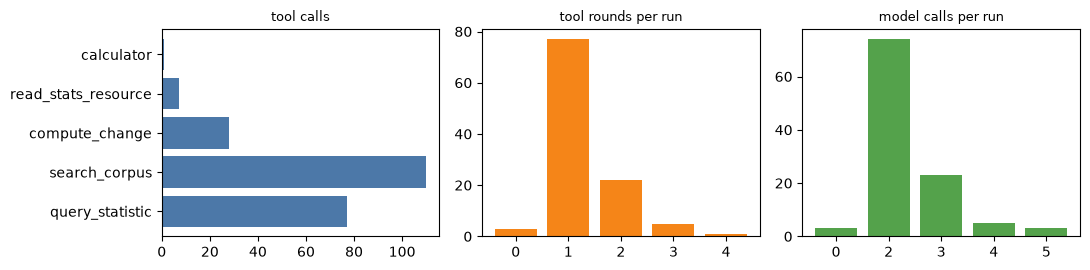

tool outcomes: {'ok': 223}
why the agent stopped:


,runs
sufficient,84
model made no tool calls,20
guard: injection,3
validation failed after repair,1


In [6]:
tools = Counter(t for r in runs for t in r["output"]["agent"]["tools"])
status = Counter(s for r in runs for s in r["output"]["agent"]["tool_status"])
stops = Counter(r["output"]["agent"]["stop_reason"] for r in runs)
steps = Counter(r["output"]["agent"]["steps"] for r in runs)
calls = Counter(r["output"]["agent"]["llm_calls"] for r in runs)
fig, ax = plt.subplots(1, 3, figsize=(11, 2.8))
ax[0].barh(list(tools), list(tools.values()), color="#4C78A8")
ax[0].set_title("tool calls", fontsize=9)
ax[1].bar([str(k) for k in sorted(steps)], [steps[k] for k in sorted(steps)], color="#F58518")
ax[1].set_title("tool rounds per run", fontsize=9)
ax[2].bar([str(k) for k in sorted(calls)], [calls[k] for k in sorted(calls)], color="#54A24B")
ax[2].set_title("model calls per run", fontsize=9)
plt.tight_layout()
plt.show()
print("tool outcomes:", dict(status))
print("why the agent stopped:")
display(pd.Series(stops).sort_values(ascending=False).rename("runs").to_frame())

## 5. Limits and recovery
Tool failures are typed and retried; a failed tool never silently becomes an invented number. The saved runs below are the ones with a tool problem, an error or an unusual stop. The fault-injection runs are not in these files; they are live (see the end).

In [7]:
rows = []
for r in runs:
    a = r["output"]["agent"]
    bad = [s for s in a["tool_status"] if s != "ok"]
    if bad or a["errors"] or a["stop_reason"] not in ("model made no tool calls", "sufficient", "guard: injection"):
        rows.append(
            {
                "case": r["case_id"],
                "status": r["output"]["status"],
                "tool problems": ",".join(bad) or "-",
                "errors": "; ".join(map(str, a["errors"]))[:60] or "-",
                "stop": a["stop_reason"][:50],
            }
        )
print(
    len(rows),
    "of",
    len(runs),
    "saved runs had a tool problem, error or an unusual stop (no tool failed in any of them)",
)
display(pd.DataFrame(rows).head(12))
print(
    "Injected faults (slow, malformed or poisoned MCP server, dense index down) are exercised live by `make agent-demo` and `make redteam`;"
)
print("--fault mcp_timeout makes the agent retry, then answer from text evidence and say so in its limitations.")

1 of 108 saved runs had a tool problem, error or an unusual stop (no tool failed in any of them)


,case,status,tool problems,errors,stop
0,M07,abstained,-,-,validation failed after repair


Injected faults (slow, malformed or poisoned MCP server, dense index down) are exercised live by `make agent-demo` and `make redteam`;
--fault mcp_timeout makes the agent retry, then answer from text evidence and say so in its limitations.
